# Assignment 3: Customer Churn Prediction with a Tuned Neural Network

**Track:** AI/ML Internship — Week 3  
**Student:** Yusra Komal

## Objective

The objective of this project is to predict whether a telecommunications customer will leave the company (churn) using a neural network built with TensorFlow/Keras. We will explore and preprocess the dataset, train a baseline model, tune the model using regularization techniques, evaluate its performance, and save it for future predictions.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2

import random
import os

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


## 1. Load, Explore and Clean the Data

In this section, we load the Telco Customer Churn dataset and inspect its dimensions, column types, missing values, duplicate records, and target distribution. We will also examine how churn varies by contract type.

In [3]:
from google.colab import files

uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [4]:
# Load the uploaded CSV file
file_name = next(iter(uploaded.keys()))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Column names
print("Column names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

# Statistical summary
print("\nNumerical summary:")
display(df.describe())

# Missing values
print("\nMissing values in each column:")
print(df.isnull().sum().sort_values(ascending=False))

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecur

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0


In [6]:
# Convert TotalCharges from text to numeric.
# Blank or invalid values become NaN.
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Missing TotalCharges after conversion:",
      df["TotalCharges"].isnull().sum())

# Remove duplicate rows if any
df = df.drop_duplicates().copy()

# Remove records with missing TotalCharges
# These records generally correspond to customers with zero tenure.
df = df.dropna(subset=["TotalCharges"]).copy()

# Remove customerID because it is an identifier, not a useful
# general predictive feature.
df = df.drop(columns=["customerID"])

print("\nShape after cleaning:", df.shape)
print("\nRemaining missing values:")
print(df.isnull().sum().sum())

display(df.head())

Missing TotalCharges after conversion: 11

Shape after cleaning: (7032, 20)

Remaining missing values:
0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Churn counts:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64


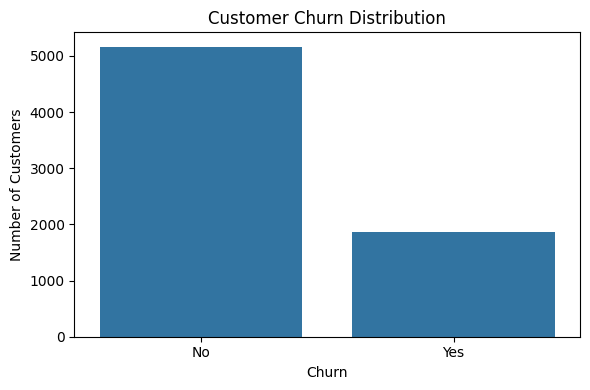

In [7]:
print("Churn counts:")
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

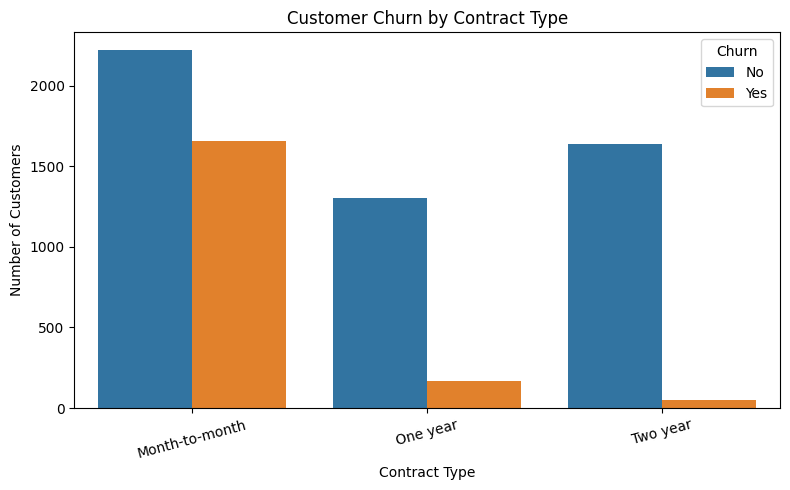

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 2. Preprocess the Data for a Neural Network

The target variable `Churn` will be encoded as 0 for No and 1 for Yes. Categorical input features will be converted using one-hot encoding, while numeric features will be standardized using `StandardScaler`.

One-hot encoding is appropriate for nominal features such as `PaymentMethod` because it does not incorrectly imply that one category is numerically greater than another. We will split the data into training and test sets before fitting the scaler to prevent data leakage.

In [9]:
# Encode target variable
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Separate input features and target
X = df.drop(columns=["Churn"])
y = df["Churn"]

# One-hot encode categorical features
X = pd.get_dummies(
    X,
    columns=X.select_dtypes(include=["object"]).columns,
    drop_first=False,
    dtype=int
)

# Ensure all features are numeric
X = X.astype("float32")

print("Encoded feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Encoded feature shape: (7032, 45)
Target shape: (7032,)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0.0,1.0,29.850000,29.850000,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.0,34.0,56.950001,1889.500000,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.0,2.0,53.849998,108.150002,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.0,45.0,42.299999,1840.750000,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,0.0,2.0,70.699997,151.649994,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [10]:
# Split before scaling: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (5625, 45)
Testing features: (1407, 45)

Training target distribution:
Churn
0    0.734
1    0.266
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.734
1    0.266
Name: proportion, dtype: float64


In [11]:
# Standardize all features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

print("All training features numeric:",
      np.isfinite(X_train_scaled).all())

print("All testing features numeric:",
      np.isfinite(X_test_scaled).all())

Scaled training shape: (5625, 45)
Scaled testing shape: (1407, 45)
All training features numeric: True
All testing features numeric: True


## 3. Build and Train a Baseline Model

We will build a Keras Sequential neural network with two hidden Dense layers using ReLU activation and one sigmoid output neuron for binary classification. The baseline model will use Adam optimization and binary cross-entropy loss without dropout or other regularization techniques, providing a reference point for the tuned model.

In [12]:
baseline_model = Sequential([
    tf.keras.Input(shape=(X_train_scaled.shape[1],)),

    Dense(64, activation="relu"),
    Dense(32, activation="relu"),

    Dense(1, activation="sigmoid")
])

baseline_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,057 (19.75 KB)

 Trainable params: 5,057 (19.75 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
baseline_history = baseline_model.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.20,
    verbose=1
)

Epoch 1/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7678 - loss: 0.4609 - val_accuracy: 0.8027 - val_loss: 0.4072
Epoch 2/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8007 - loss: 0.4214 - val_accuracy: 0.8009 - val_loss: 0.4051
Epoch 3/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8067 - loss: 0.4115 - val_accuracy: 0.7991 - val_loss: 0.4075
Epoch 4/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8111 - loss: 0.4052 - val_accuracy: 0.8000 - val_loss: 0.4103
Epoch 5/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8153 - loss: 0.4002 - val_accuracy: 0.8009 - val_loss: 0.4130
Epoch 6/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8184 - loss: 0.3958 - val_accuracy: 0.8000 - val_loss: 0.4158
Epoch 7/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8193 - loss: 0.3917 - val_accuracy: 0.7991 - val_loss: 0.4184
Epoch 8/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8200 - loss: 0.3877 - val_accuracy: 0.

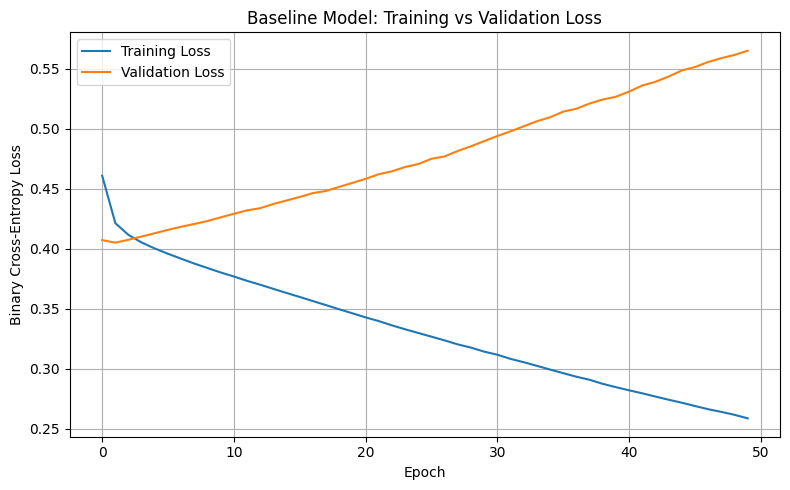

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    baseline_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    baseline_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Baseline Model: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

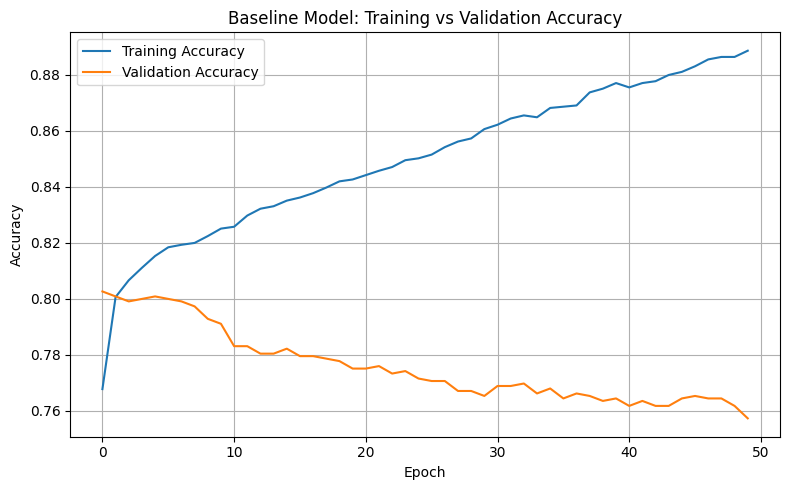

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    baseline_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    baseline_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Baseline Model: Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
baseline_loss, baseline_accuracy = baseline_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f"Baseline Test Loss: {baseline_loss:.4f}")
print(f"Baseline Test Accuracy: {baseline_accuracy:.4f}")
print(f"Baseline Test Accuracy: {baseline_accuracy * 100:.2f}%")

Baseline Test Loss: 0.5846
Baseline Test Accuracy: 0.7555
Baseline Test Accuracy: 75.55%


## 4. Tune the Model

We will improve the baseline using three techniques:

1. **Dropout:** randomly disables a fraction of hidden-layer units during training to help reduce overfitting.
2. **L2 regularization:** penalizes excessively large weights.
3. **Early Stopping:** monitors validation loss and restores the weights from the best validation epoch.

We will retain the same training and test split so that the baseline and tuned models can be compared fairly.

In [17]:
tuned_model = Sequential([
    tf.keras.Input(shape=(X_train_scaled.shape[1],)),

    Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),
    BatchNormalization(),
    Dropout(0.30),

    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),
    Dropout(0.20),

    Dense(1, activation="sigmoid")
])

tuned_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

tuned_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,313 (20.75 KB)

 Trainable params: 5,185 (20.25 KB)

 Non-trainable params: 128 (512.00 B)

In [18]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

tuned_history = tuned_model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.20,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6664 - loss: 0.7139 - val_accuracy: 0.7947 - val_loss: 0.5174
Epoch 2/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7680 - loss: 0.5662 - val_accuracy: 0.7956 - val_loss: 0.5009
Epoch 3/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7778 - loss: 0.5439 - val_accuracy: 0.7964 - val_loss: 0.4904
Epoch 4/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7809 - loss: 0.5252 - val_accuracy: 0.8036 - val_loss: 0.4833
Epoch 5/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7878 - loss: 0.5117 - val_accuracy: 0.7991 - val_loss: 0.4793
Epoch 6/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7949 - loss: 0.5027 - val_accuracy: 0.8018 - val_loss: 0.4728
Epoch 7/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7967 - loss: 0.4948 - val_accuracy: 0.8036 - val_loss: 0.4702
Epoch 8/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8020 - loss: 0.4897 - val_accu

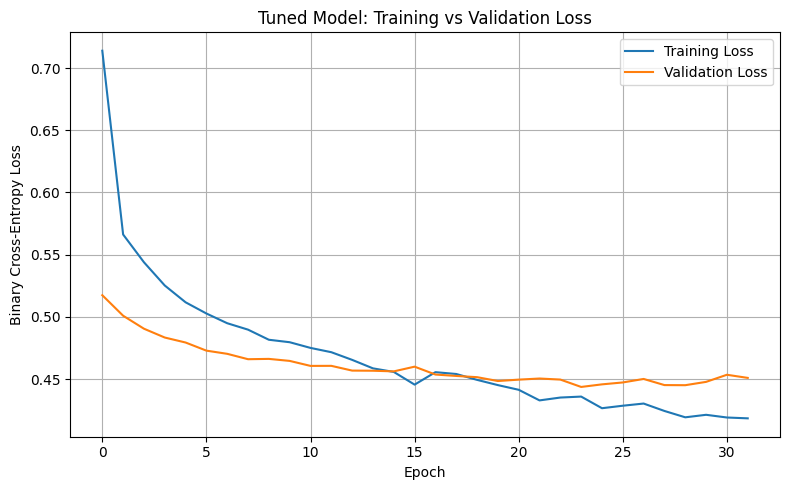

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    tuned_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    tuned_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Tuned Model: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

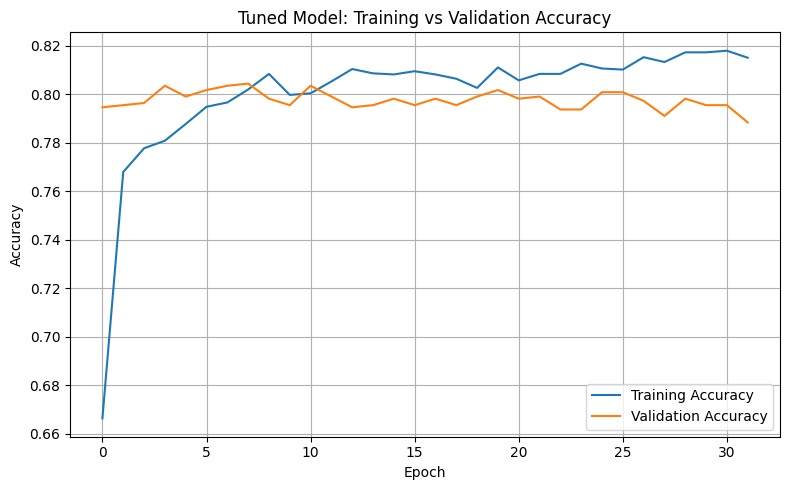

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    tuned_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    tuned_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Tuned Model: Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
tuned_loss, tuned_accuracy = tuned_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

comparison = pd.DataFrame({
    "Model": ["Baseline Neural Network", "Tuned Neural Network"],
    "Test Loss": [baseline_loss, tuned_loss],
    "Test Accuracy": [baseline_accuracy, tuned_accuracy],
    "Test Accuracy (%)": [
        baseline_accuracy * 100,
        tuned_accuracy * 100
    ]
})

display(comparison.round(4))

accuracy_change = (
    tuned_accuracy - baseline_accuracy
) * 100

print(f"Accuracy change: {accuracy_change:+.2f} percentage points")

,Model,Test Loss,Test Accuracy,Test Accuracy (%)
0,Baseline Neural Network,0.5846,0.7555,75.5508
1,Tuned Neural Network,0.4744,0.7790,77.8962


Accuracy change: +2.35 percentage points


## 5. Evaluate the Best Model

We will evaluate the tuned neural network using precision, recall, F1-score, and a confusion matrix on the held-out test set. These metrics help assess how effectively the model identifies customers who are likely to churn, rather than relying on accuracy alone.

In [22]:
# Predict probabilities and convert them to binary labels
y_prob = tuned_model.predict(X_test_scaled, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred, zero_division=0)
test_recall = recall_score(y_test, y_pred, zero_division=0)
test_f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1-score : {test_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

Accuracy : 0.7790
Precision: 0.5952
Recall   : 0.5267
F1-score : 0.5589

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.87      0.85      1033
       Churn       0.60      0.53      0.56       374

    accuracy                           0.78      1407
   macro avg       0.72      0.70      0.71      1407
weighted avg       0.77      0.78      0.77      1407



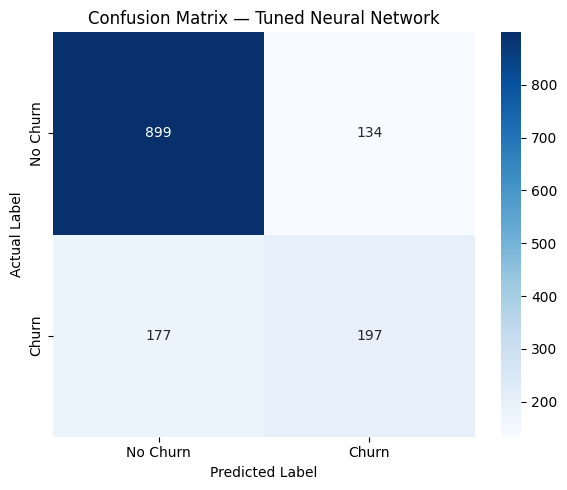

Confusion matrix:
[[899 134]
 [177 197]]


In [23]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Confusion Matrix — Tuned Neural Network")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)

### Why Accuracy Alone Can Be Misleading

The churn classes are imbalanced if the dataset contains substantially more non-churning customers than churning customers. In that case, a model could achieve seemingly good accuracy by predicting the majority class while missing many customers who actually churn. Precision, recall, F1-score, and the confusion matrix provide a more complete evaluation of churn prediction performance.

## 6. Save and Predict

We will save the tuned Keras model in the `.keras` format and reload it to verify that it can be used for inference. The saved model contains the neural network architecture and learned weights. The preprocessing steps, including the feature columns and scaler, must also be retained for new-customer predictions.

In [24]:
model_path = "best_churn_model.keras"

tuned_model.save(model_path)

print("Model saved successfully:", model_path)

Model saved successfully: best_churn_model.keras


In [25]:
# Reload the saved model
loaded_model = load_model("best_churn_model.keras")

# Verify it produces predictions
sample_predictions = loaded_model.predict(
    X_test_scaled[:5],
    verbose=0
)

print("Model loaded successfully!")
print("First five churn probabilities:")
print(sample_predictions.ravel())

Model loaded successfully!
First five churn probabilities:
[0.00271673 0.69673884 0.00366821 0.2334032  0.04651067]


In [26]:
# Start with a valid customer feature row as a template.
# The values below are then changed to represent a hypothetical customer.
new_customer = df.drop(columns=["Churn"]).iloc[[0]].copy()

new_customer.loc[:, "gender"] = "Female"
new_customer.loc[:, "SeniorCitizen"] = 0
new_customer.loc[:, "Partner"] = "No"
new_customer.loc[:, "Dependents"] = "No"
new_customer.loc[:, "tenure"] = 2
new_customer.loc[:, "PhoneService"] = "Yes"
new_customer.loc[:, "InternetService"] = "Fiber optic"
new_customer.loc[:, "Contract"] = "Month-to-month"
new_customer.loc[:, "PaperlessBilling"] = "Yes"
new_customer.loc[:, "PaymentMethod"] = "Electronic check"
new_customer.loc[:, "MonthlyCharges"] = 85.0
new_customer.loc[:, "TotalCharges"] = 170.0

display(new_customer)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,No,No,2,Yes,No phone service,Fiber optic,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,85.0,170.0


In [27]:
def predict_new_customer(customer_data):
    """
    Predict churn probability for one customer.
    customer_data must contain the original feature columns.
    """

    # One-hot encode categorical features
    customer_encoded = pd.get_dummies(
        customer_data,
        columns=customer_data.select_dtypes(
            include=["object"]
        ).columns,
        dtype=int
    )

    # Match training feature names and order
    customer_encoded = customer_encoded.reindex(
        columns=X.columns,
        fill_value=0
    )

    # Convert to numeric and scale using the fitted scaler
    customer_encoded = customer_encoded.astype("float32")
    customer_scaled = scaler.transform(customer_encoded)

    # Predict churn probability
    probability = float(
        loaded_model.predict(customer_scaled, verbose=0)[0][0]
    )

    predicted_class = "Yes" if probability >= 0.5 else "No"

    return {
        "Churn Probability": round(probability, 4),
        "Predicted Churn": predicted_class
    }


prediction = predict_new_customer(new_customer)

print("Hypothetical Customer Prediction")
print("Churn Probability:", prediction["Churn Probability"])
print("Predicted Churn:", prediction["Predicted Churn"])

Hypothetical Customer Prediction
Churn Probability: 0.6671
Predicted Churn: Yes


## 7. Short Answer: CNN vs. RNN

A **Convolutional Neural Network (CNN)** is suitable for spatial data such as images because convolutional layers learn local patterns, shapes, and visual features. For example, a CNN can classify images of cats and dogs. A **Recurrent Neural Network (RNN)** is useful for sequential data where the order of information matters, such as time-series measurements or sequences of words. For example, an RNN can process a sequence of words for sentiment analysis or analyze sensor readings over time.

## 8. Conclusion

In this project, we developed a customer churn prediction system using TensorFlow/Keras. We explored and cleaned the Telco Customer Churn dataset, encoded categorical features, standardized numerical features, and trained a baseline neural network. We then applied regularization and Early Stopping to train a tuned model and evaluated its performance using classification metrics and a confusion matrix. Finally, we saved the trained model and tested a prediction on a hypothetical customer.

The baseline-versus-tuned comparison and evaluation metrics are reported from the actual model results generated in this notebook.

In [28]:
from google.colab import files
import os

# Confirm that the model exists
assert os.path.exists("best_churn_model.keras")

print("Model file is ready for submission.")
print("Notebook filename: Assignment3_YusraKomal.ipynb")
print("Model filename: best_churn_model.keras")

# Download the saved model
files.download("best_churn_model.keras")

Model file is ready for submission.
Notebook filename: Assignment3_YusraKomal.ipynb
Model filename: best_churn_model.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>